
Running experiment 1/30
GWO cost: 1138.1207
GA cost : 1138.1205

Running experiment 2/30
GWO cost: 1138.1206
GA cost : 1138.1205

Running experiment 3/30
GWO cost: 1138.1206
GA cost : 1138.1205

Running experiment 4/30
GWO cost: 1138.1205
GA cost : 1138.1205

Running experiment 5/30
GWO cost: 1138.1206
GA cost : 1138.1205

Running experiment 6/30
GWO cost: 1138.1206
GA cost : 1138.1205

Running experiment 7/30
GWO cost: 1138.1205
GA cost : 1138.1205

Running experiment 8/30
GWO cost: 1138.1207
GA cost : 1138.1205

Running experiment 9/30
GWO cost: 1138.1206
GA cost : 1138.1205

Running experiment 10/30
GWO cost: 1138.1206
GA cost : 1138.1205

Running experiment 11/30
GWO cost: 1138.1206
GA cost : 1138.1205

Running experiment 12/30
GWO cost: 1138.1206
GA cost : 1138.1205

Running experiment 13/30
GWO cost: 1138.1206
GA cost : 1138.1205

Running experiment 14/30
GWO cost: 1138.1207
GA cost : 1138.1205

Running experiment 15/30
GWO cost: 1138.1206
GA cost : 1138.1205

Running experiment

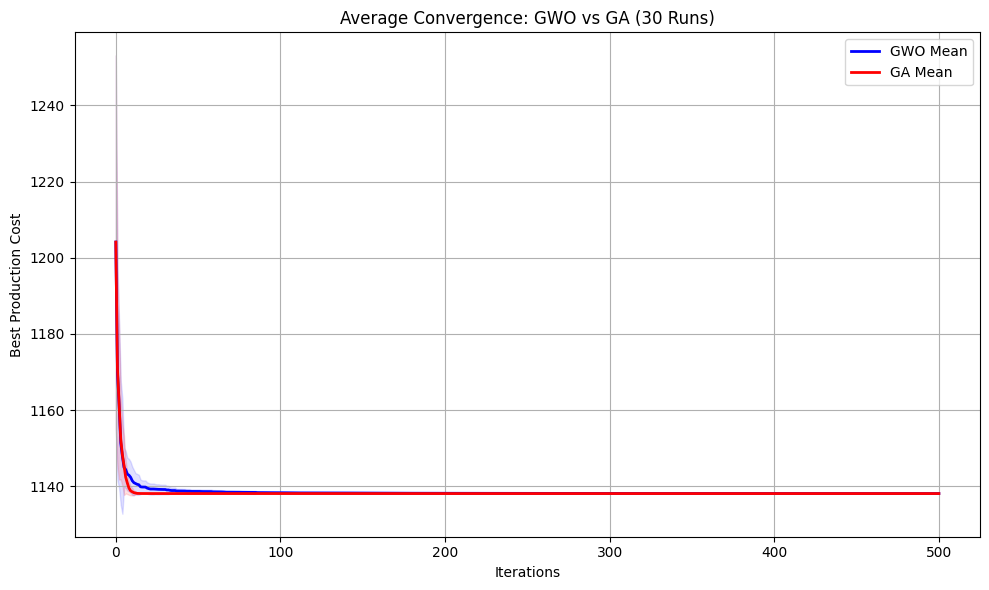

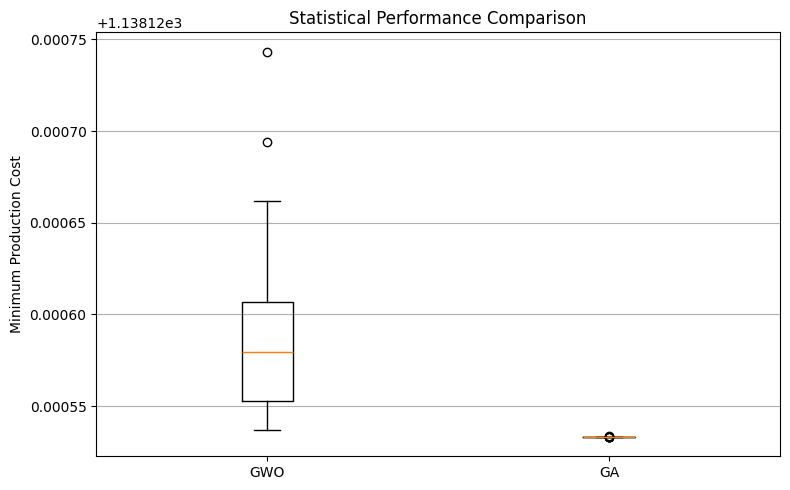

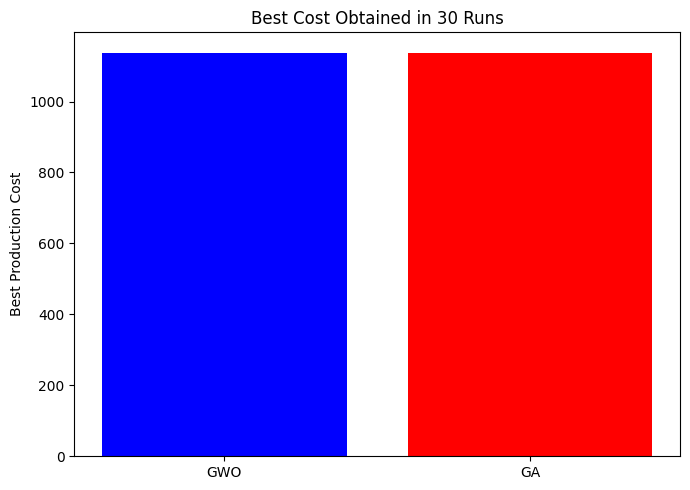


Results saved successfully!


In [5]:

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import time

# =====================================================
# 1. EXPERIMENTAL SETTINGS
# =====================================================

POP_SIZE = 100
MAX_ITER = 500
NUM_RUNS = 30
DIM = 3

LOWER = np.array([100, 100, 10], dtype=float)
UPPER = np.array([1000, 250, 60], dtype=float)

# =====================================================
# 2. NONLINEAR PRODUCTION COST FUNCTION
# =====================================================

def production_cost(x):

    speed = x[0]
    temperature = x[1]
    processing_time = x[2]

    cost = (
        0.05 * (speed - 500)**2
        + 0.08 * (temperature - 150)**2
        + 0.12 * (processing_time - 30)**2
        + 0.0005 * speed * temperature
        + 0.002 * temperature * processing_time
        + 0.01 * speed * processing_time
        + 1000
    )

    return cost


# =====================================================
# 3. GREY WOLF OPTIMIZER
# =====================================================

def GWO(seed):

    rng = np.random.default_rng(seed)

    wolves = rng.uniform(
        LOWER, UPPER, (POP_SIZE, DIM)
    )

    alpha_pos = None
    beta_pos = None
    delta_pos = None

    alpha_score = np.inf
    beta_score = np.inf
    delta_score = np.inf

    convergence = []

    # Evaluate initial population
    for wolf in wolves:

        fitness = production_cost(wolf)

        if fitness < alpha_score:

            delta_score = beta_score
            delta_pos = (
                None if beta_pos is None
                else beta_pos.copy()
            )

            beta_score = alpha_score
            beta_pos = (
                None if alpha_pos is None
                else alpha_pos.copy()
            )

            alpha_score = fitness
            alpha_pos = wolf.copy()

        elif fitness < beta_score:

            delta_score = beta_score
            delta_pos = (
                None if beta_pos is None
                else beta_pos.copy()
            )

            beta_score = fitness
            beta_pos = wolf.copy()

        elif fitness < delta_score:

            delta_score = fitness
            delta_pos = wolf.copy()

    convergence.append(alpha_score)

    # Main optimization loop
    for iteration in range(MAX_ITER):

        a = 2 - 2 * iteration / MAX_ITER

        for i in range(POP_SIZE):

            r1 = rng.random(DIM)
            r2 = rng.random(DIM)

            A1 = 2 * a * r1 - a
            C1 = 2 * r2

            D_alpha = abs(
                C1 * alpha_pos - wolves[i]
            )

            X1 = alpha_pos - A1 * D_alpha

            r1 = rng.random(DIM)
            r2 = rng.random(DIM)

            A2 = 2 * a * r1 - a
            C2 = 2 * r2

            D_beta = abs(
                C2 * beta_pos - wolves[i]
            )

            X2 = beta_pos - A2 * D_beta

            r1 = rng.random(DIM)
            r2 = rng.random(DIM)

            A3 = 2 * a * r1 - a
            C3 = 2 * r2

            D_delta = abs(
                C3 * delta_pos - wolves[i]
            )

            X3 = delta_pos - A3 * D_delta

            wolves[i] = (X1 + X2 + X3) / 3

            wolves[i] = np.clip(
                wolves[i], LOWER, UPPER
            )

        # Update the three leading wolves
        for wolf in wolves:

            fitness = production_cost(wolf)

            if fitness < alpha_score:

                delta_score = beta_score
                delta_pos = beta_pos.copy()

                beta_score = alpha_score
                beta_pos = alpha_pos.copy()

                alpha_score = fitness
                alpha_pos = wolf.copy()

            elif fitness < beta_score:

                delta_score = beta_score
                delta_pos = beta_pos.copy()

                beta_score = fitness
                beta_pos = wolf.copy()

            elif fitness < delta_score:

                delta_score = fitness
                delta_pos = wolf.copy()

        convergence.append(alpha_score)

    return alpha_pos, alpha_score, convergence


# =====================================================
# 4. GENETIC ALGORITHM
# =====================================================

def GA(seed):

    rng = np.random.default_rng(seed)

    population = rng.uniform(
        LOWER, UPPER, (POP_SIZE, DIM)
    )

    crossover_rate = 0.8
    mutation_rate = 0.15
    mutation_scale = 0.08

    best_position = None
    best_cost = np.inf

    convergence = []

    # Initial evaluation
    fitness = np.array([
        production_cost(ind)
        for ind in population
    ])

    idx = np.argmin(fitness)

    best_position = population[idx].copy()
    best_cost = fitness[idx]

    convergence.append(best_cost)

    # Tournament selection
    def tournament_selection(pop, fit):

        candidates = rng.choice(
            len(pop), 3, replace=False
        )

        winner = candidates[
            np.argmin(fit[candidates])
        ]

        return pop[winner].copy()

    # Main GA loop
    for iteration in range(MAX_ITER):

        fitness = np.array([
            production_cost(ind)
            for ind in population
        ])

        current_idx = np.argmin(fitness)

        if fitness[current_idx] < best_cost:

            best_cost = fitness[current_idx]
            best_position = population[
                current_idx
            ].copy()

        new_population = []

        # Elitism
        new_population.append(
            best_position.copy()
        )

        while len(new_population) < POP_SIZE:

            parent1 = tournament_selection(
                population, fitness
            )

            parent2 = tournament_selection(
                population, fitness
            )

            # Arithmetic crossover
            if rng.random() < crossover_rate:

                weight = rng.random(DIM)

                child = (
                    weight * parent1
                    + (1 - weight) * parent2
                )

            else:

                child = parent1.copy()

            # Gaussian mutation
            for j in range(DIM):

                if rng.random() < mutation_rate:

                    child[j] += rng.normal(
                        0,
                        mutation_scale *
                        (UPPER[j] - LOWER[j])
                    )

            child = np.clip(
                child, LOWER, UPPER
            )

            new_population.append(child)

        population = np.array(new_population)

        # Evaluate new population
        fitness = np.array([
            production_cost(ind)
            for ind in population
        ])

        idx = np.argmin(fitness)

        if fitness[idx] < best_cost:

            best_cost = fitness[idx]
            best_position = population[idx].copy()

        convergence.append(best_cost)

    return best_position, best_cost, convergence


# =====================================================
# 5. RUN BOTH ALGORITHMS 30 TIMES
# =====================================================

gwo_results = []
ga_results = []

gwo_curves = []
ga_curves = []

gwo_times = []
ga_times = []

for run in range(NUM_RUNS):

    seed = 100 + run

    print(f"\nRunning experiment {run + 1}/{NUM_RUNS}")

    # GWO
    start = time.perf_counter()

    gwo_pos, gwo_cost, gwo_curve = GWO(seed)

    gwo_elapsed = time.perf_counter() - start

    gwo_results.append({
        "cost": gwo_cost,
        "position": gwo_pos
    })

    gwo_curves.append(gwo_curve)
    gwo_times.append(gwo_elapsed)

    # GA
    start = time.perf_counter()

    ga_pos, ga_cost, ga_curve = GA(seed)

    ga_elapsed = time.perf_counter() - start

    ga_results.append({
        "cost": ga_cost,
        "position": ga_pos
    })

    ga_curves.append(ga_curve)
    ga_times.append(ga_elapsed)

    print("GWO cost:", round(gwo_cost, 4))
    print("GA cost :", round(ga_cost, 4))


# =====================================================
# 6. STATISTICAL ANALYSIS
# =====================================================

gwo_costs = np.array([
    r["cost"] for r in gwo_results
])

ga_costs = np.array([
    r["cost"] for r in ga_results
])

gwo_best_index = np.argmin(gwo_costs)
ga_best_index = np.argmin(ga_costs)

summary = pd.DataFrame({

    "Performance": [
        "Best Cost",
        "Mean Cost",
        "Worst Cost",
        "Standard Deviation",
        "Average Execution Time (s)"
    ],

    "GWO": [
        np.min(gwo_costs),
        np.mean(gwo_costs),
        np.max(gwo_costs),
        np.std(gwo_costs, ddof=1),
        np.mean(gwo_times)
    ],

    "GA": [
        np.min(ga_costs),
        np.mean(ga_costs),
        np.max(ga_costs),
        np.std(ga_costs, ddof=1),
        np.mean(ga_times)
    ]
})

print("\n========== STATISTICAL COMPARISON ==========")

print(summary.to_string(index=False))

# =====================================================
# 7. BEST OPTIMAL PARAMETERS
# =====================================================

print("\n========== BEST GWO SOLUTION ==========")

print("Machine Speed:",
      gwo_results[gwo_best_index]["position"][0])

print("Temperature:",
      gwo_results[gwo_best_index]["position"][1])

print("Processing Time:",
      gwo_results[gwo_best_index]["position"][2])

print("Minimum Cost:", gwo_costs[gwo_best_index])


print("\n========== BEST GA SOLUTION ==========")

print("Machine Speed:",
      ga_results[ga_best_index]["position"][0])

print("Temperature:",
      ga_results[ga_best_index]["position"][1])

print("Processing Time:",
      ga_results[ga_best_index]["position"][2])

print("Minimum Cost:", ga_costs[ga_best_index])


# =====================================================
# 8. WIN COUNT
# =====================================================

gwo_wins = np.sum(gwo_costs < ga_costs)
ga_wins = np.sum(ga_costs < gwo_costs)
ties = np.sum(np.isclose(gwo_costs, ga_costs))

print("\n========== RUN-WISE COMPARISON ==========")

print("GWO wins:", gwo_wins)
print("GA wins:", ga_wins)
print("Ties:", ties)


# =====================================================
# 9. AUTOMATIC PERFORMANCE CONCLUSION
# =====================================================

print("\n========== FINAL COMPARISON ==========")

if np.mean(gwo_costs) < np.mean(ga_costs):

    print("GWO achieved a lower average production cost.")

elif np.mean(ga_costs) < np.mean(gwo_costs):

    print("GA achieved a lower average production cost.")

else:

    print("Both algorithms achieved equal average cost.")

if np.std(gwo_costs, ddof=1) < np.std(ga_costs, ddof=1):

    print("GWO has better consistency.")

elif np.std(ga_costs, ddof=1) < np.std(gwo_costs, ddof=1):

    print("GA has better consistency.")

else:

    print("Both algorithms have equal consistency.")


# =====================================================
# 10. AVERAGE CONVERGENCE CURVES
# =====================================================

gwo_mean_curve = np.mean(
    np.array(gwo_curves), axis=0
)

ga_mean_curve = np.mean(
    np.array(ga_curves), axis=0
)

gwo_std_curve = np.std(
    np.array(gwo_curves), axis=0
)

ga_std_curve = np.std(
    np.array(ga_curves), axis=0
)

iterations = np.arange(MAX_ITER + 1)

plt.figure(figsize=(10, 6))

plt.plot(
    iterations,
    gwo_mean_curve,
    color="blue",
    linewidth=2,
    label="GWO Mean"
)

plt.plot(
    iterations,
    ga_mean_curve,
    color="red",
    linewidth=2,
    label="GA Mean"
)

plt.fill_between(
    iterations,
    gwo_mean_curve - gwo_std_curve,
    gwo_mean_curve + gwo_std_curve,
    color="blue",
    alpha=0.12
)

plt.fill_between(
    iterations,
    ga_mean_curve - ga_std_curve,
    ga_mean_curve + ga_std_curve,
    color="red",
    alpha=0.12
)

plt.xlabel("Iterations")
plt.ylabel("Best Production Cost")

plt.title(
    "Average Convergence: GWO vs GA (30 Runs)"
)

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# =====================================================
# 11. BOX PLOT
# =====================================================

plt.figure(figsize=(8, 5))

plt.boxplot(
    [gwo_costs, ga_costs],
    tick_labels=["GWO", "GA"]
)

plt.ylabel("Minimum Production Cost")

plt.title(
    "Statistical Performance Comparison"
)

plt.grid(axis="y")
plt.tight_layout()
plt.show()


# =====================================================
# 12. BEST COST BAR CHART
# =====================================================

plt.figure(figsize=(7, 5))

plt.bar(
    ["GWO", "GA"],
    [
        np.min(gwo_costs),
        np.min(ga_costs)
    ],
    color=["blue", "red"]
)

plt.ylabel("Best Production Cost")

plt.title("Best Cost Obtained in 30 Runs")

plt.tight_layout()
plt.show()


# =====================================================
# 13. SAVE RESULTS
# =====================================================

summary.to_csv(
    "GWO_GA_statistical_comparison.csv",
    index=False
)

pd.DataFrame({
    "Run": np.arange(1, NUM_RUNS + 1),
    "GWO_Cost": gwo_costs,
    "GA_Cost": ga_costs,
    "GWO_Time": gwo_times,
    "GA_Time": ga_times
}).to_csv(
    "GWO_GA_all_runs.csv",
    index=False
)

print("\nResults saved successfully!")
